In [5]:
%pip install wikipedia

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Using cached beautifulsoup4-4.15.0-py3-none-any.whl.metadata (3.8 kB)
Using cached beautifulsoup4-4.15.0-py3-none-any.whl (109 kB)
  Created wheel for wikipedia: filename=wikipedia-1.4.0-py3-none-any.whl size=11757 sha256=8b184f20b75e51e45c42d7f2f6ffc23c419e63d0d63e57e3e23d2639e5425131
  Stored in directory: /Users/ming/Library/Caches/pip/wheels/79/1d/c8/b64e19423cc5a2a339450ea5d145e7c8eb3d4aa2b150cde33b
Successfully built wikipedia
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [wikipedia]
Note: you may need to restart the kernel to use updated packages.


In [7]:
%pip install langchain-community

  Using cached langchain_community-0.4.2-py3-none-any.whl.metadata (3.4 kB)
Using cached langchain_community-0.4.2-py3-none-any.whl (2.4 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 14.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 36.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [langchain-community]ngchain-community]
Note: you may need to restart the kernel to use updated packages.


In [8]:
# Imports and environment first

from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command

# from sidekick_tools import search, send_push_notification, wikipedia_lookup
from sidekick_tools import send_push_notification, wikipedia_lookup
from sidekick import Sidekick

load_dotenv(override=True)

True

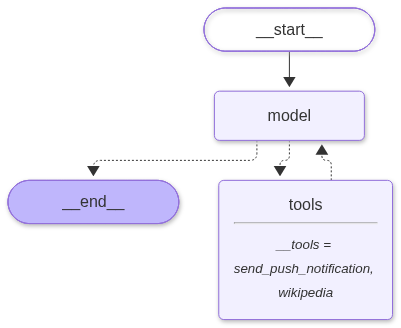

In [9]:
simple_worker = create_agent(
    model="openai:gpt-5.4-mini",
    # tools=[search, send_push_notification, wikipedia_lookup],
    tools=[send_push_notification, wikipedia_lookup],
    system_prompt="You are Sidekick, a helpful personal assistant. Use your tools to complete the task.",
    checkpointer=InMemorySaver(),
)

simple_worker

In [10]:
async def ask(worker, message):
    config = {"configurable": {"thread_id": "simple-sidekick"}}
    result = await worker.ainvoke({"messages": [{"role": "user", "content": message}]}, config=config)
    return result["messages"][-1].content

reply = await ask(simple_worker, "Search for who won the Nobel Prize in Physics in 2023 and send a push notification with a short summary.")
print(reply)

Done — I found that the 2023 Nobel Prize in Physics was awarded to Pierre Agostini, Ferenc Krausz, and Anne L'Huillier for experimental methods that generate attosecond pulses of light to study electron dynamics, and I sent a push notification with the summary.


In [ ]:
from langchain_core.tools import tool

@tool
def book_meeting(person: str, day: str) -> str:
    """Book a meeting with a person on a given day."""
    return f"Meeting booked with {person} on {day}."

approval_agent = create_agent(
    model="openai:gpt-5.4-mini",
    tools=[book_meeting],
    system_prompt="You are a scheduling assistant. Use the book_meeting tool.",
    middleware=[HumanInTheLoopMiddleware(interrupt_on={"book_meeting": True})],
    checkpointer=InMemorySaver(),
)

config = {"configurable": {"thread_id": "approval-demo"}}
result = await approval_agent.ainvoke(
    {"messages": [{"role": "user", "content": "Book a meeting with Sam on Friday."}]}, config
)

interrupt = result["__interrupt__"][0]
print("The agent paused and is asking for approval:")
print(interrupt.value["action_requests"][0]["description"])